<a href="https://colab.research.google.com/github/CinthiaGloricel/loan-risk-exploratory-analysis/blob/main/loan-risk-exploratory-analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Cargar la base de datos*

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Cargar el archivo
df = pd.read_csv("train.csv")  # Cambia "train.csv" si tu archivo tiene otro nombre

print(f"Dataset cargado con éxito: {df.shape[0]} filas y {df.shape[1]} columnas\n")
df.head()

Dataset cargado con éxito: 614 filas y 13 columnas



,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [17]:
# 1. Imputación de variables categóricas con la moda
cat_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# 2. Imputación de variables continuas con la mediana (robusta contra outliers)
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].median())

# 3. Creación de variables de negocio (Feature Engineering)
# Ingreso total del hogar
df['Total_Income'] = df['ApplicantIncome'] + df['CoapplicantIncome']

# Ratio Monto Solicitado vs Ingreso Total
df['Loan_to_Income_Ratio'] = (df['LoanAmount'] * 1000) / df['Total_Income']

print("Valores nulos restantes:", df.isnull().sum().sum())
print("Nuevas variables creadas: Total_Income, Loan_to_Income_Ratio")

Valores nulos restantes: 0
Nuevas variables creadas: Total_Income, Loan_to_Income_Ratio


<Figure size 700x450 with 0 Axes>

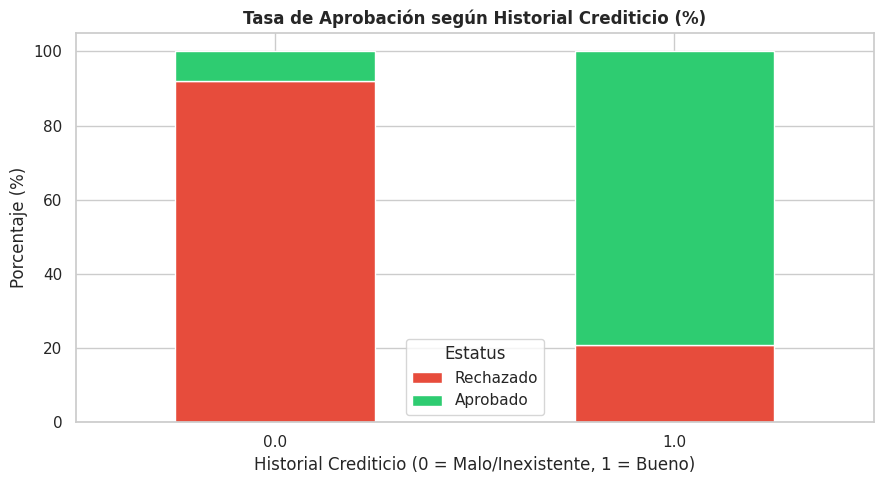

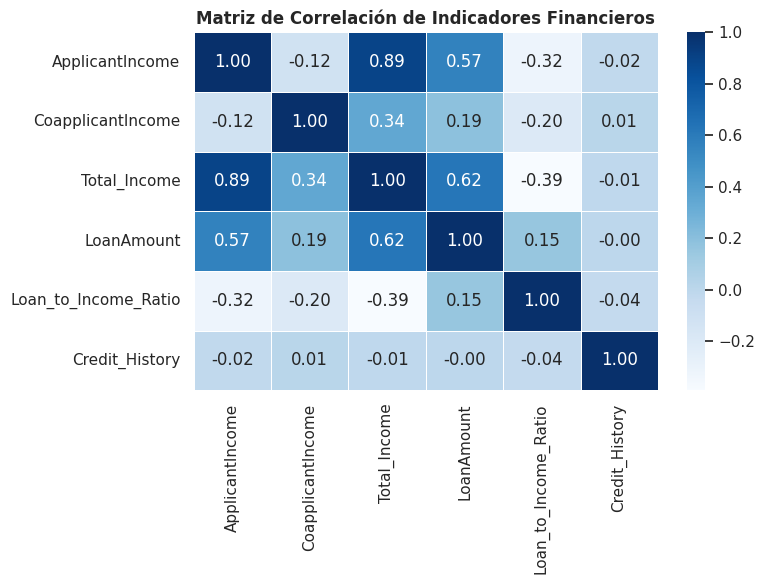

In [18]:
# Gráfica 1: Historial Crediticio vs Aprobación
tabla_credito = pd.crosstab(df['Credit_History'], df['Loan_Status'], normalize='index') * 100

plt.figure(figsize=(7, 4.5))
ax = tabla_credito.plot(kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], rot=0)
plt.title('Tasa de Aprobación según Historial Crediticio (%)', fontsize=12, fontweight='bold')
plt.xlabel('Historial Crediticio (0 = Malo/Inexistente, 1 = Bueno)')
plt.ylabel('Porcentaje (%)')
plt.legend(['Rechazado', 'Aprobado'], title='Estatus')
plt.tight_layout()
plt.savefig('credit_history_impact.png', dpi=300)
plt.show()

# Gráfica 2: Matriz de Correlación de Indicadores Numéricos
columnas_analisis = ['ApplicantIncome', 'CoapplicantIncome', 'Total_Income', 'LoanAmount', 'Loan_to_Income_Ratio', 'Credit_History']
df_corr = df[columnas_analisis].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(df_corr, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Matriz de Correlación de Indicadores Financieros', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation.png', dpi=300)
plt.show()

In [19]:
print(list(df.columns))

['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status', 'Total_Income', 'Loan_to_Income_Ratio']
